# 04 · Final evaluation, explanations and conclusions

This notebook narrates the evaluation of the models chosen in `03_modelling.ipynb`
(`tables/selected_models.json`) on the **2014 test cohort**, which is used here once and
only for scoring. All logic lives in `src/evaluation.py`; this notebook calls it step by step.

Contents
1. Metrics per cohort × model × feature set × year (validation 2011–13 and test 2014)
2. Uncertainty: player-clustered bootstrap, paired differences against EA's potential gap
3. Scouting simulation on 2014: our watchlist vs EA's list vs a random list (headline figure)
4. Explainability: permutation importance, standardised logistic coefficients, feature-set comparison
5. Sensitivity analyses: other label definitions and dropping short rating horizons
6. Supplementary EA-independent check: next-season league starts
7. What a scout should do, assumptions and limitations

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").exists())
sys.path.insert(0, str(ROOT))
import warnings
warnings.simplefilter("ignore")
import pandas as pd
from IPython.display import Image, display
from src import evaluation as E
from src.common import B_FIGURES, COHORTS

pd.set_option("display.width", 200, "display.max_columns", 40, "display.float_format", lambda x: f"{x:.3f}")
N_BOOT, N_REPEATS, COEF_BOOT = 1000, 10, 200   # bootstrap replicates, permutation repeats, coefficient refits

r = E.main(N_BOOT, N_REPEATS, COEF_BOOT)        # ~7 min: computes and saves every table and figure below
for c, s in r["selection"].items():
    print(f"selected for {c:5s}: {s['model']} on '{s['feature_set']}' (trained on {s['train_scope']}), params {s['params']}")

selected for all  : logreg on 'combined' (trained on all), params {'C': 0.1, 'class_weight': None, 'pca_skills': 3}
selected for young: hist_gb on 'combined' (trained on young), params {'class_weight': 'balanced', 'learning_rate': 0.03, 'max_leaf_nodes': 3}


### How the results below are produced
`E.main` refits the selected pipelines with `src.modelling.build_pipeline` on 2009–2013 only (or on earlier years inside the validation folds) and scores 2014; nothing is fitted or chosen on the test year.

In [2]:
pd.DataFrame(r["selection"]).T[["model", "feature_set", "train_scope", "params"]]

,model,feature_set,train_scope,params
all,logreg,combined,all,"{'C': 0.1, 'class_weight': None, 'pca_skills': 3}"
young,hist_gb,combined,young,"{'class_weight': 'balanced', 'learning_rate': ..."


## 1 · Metrics by year
Precision@10% is the share of the watched players (floor of 10% of each year's cohort) who break
out; Recall@10% is the share of all breakouts that the watchlist catches; average precision (PR-AUC)
summarises the whole ranking. The random baseline's expected precision equals the prevalence.

In [3]:
ym = r["year_metrics"]
vs = (ym[ym.period == "validation"].groupby(["cohort", "train_scope", "model", "feature_set"])
      .agg(mean_precision_at_10pct=("precision_at_10pct", "mean"), mean_recall_at_10pct=("recall_at_10pct", "mean"),
           mean_average_precision=("average_precision", "mean"), hits=("hits", "sum"), watchlist=("watchlist", "sum"))
      .reset_index().sort_values(["cohort", "mean_precision_at_10pct"], ascending=[True, False]))
vs.groupby("cohort").head(8)

,cohort,train_scope,model,feature_set,mean_precision_at_10pct,mean_recall_at_10pct,mean_average_precision,hits,watchlist
6,all,all,logreg,combined,0.579,0.353,0.507,643.000,1114
2,all,all,hist_gb,combined,0.567,0.347,0.477,630.000,1114
10,all,all,random_forest,combined,0.558,0.341,0.477,619.000,1114
9,all,all,logreg,rating_only,0.530,0.326,0.443,588.000,1114
8,all,all,logreg,rating_no_potential,0.528,0.323,0.439,586.000,1114
13,all,all,random_forest,rating_only,0.522,0.322,0.435,580.000,1114
5,all,all,hist_gb,rating_only,0.516,0.317,0.425,573.000,1114
4,all,all,hist_gb,rating_no_potential,0.514,0.316,0.420,571.000,1114
29,young,young,hist_gb,combined,0.702,0.252,0.560,299.000,426
20,young,all,logreg,combined,0.700,0.251,0.580,298.000,426


In [4]:
ym = r["year_metrics"]
sel_rows = []
for c, s in r["selection"].items():
    g = ym[ym.cohort == c]
    pick = ((g.model == s["model"]) & (g.feature_set == s["feature_set"]) & (g.train_scope == s["train_scope"])) \
        | ((g.model == "ea_gap") & (g.train_scope == c)) | (g.model == "random")
    sel_rows.append(g[pick])
table = pd.concat(sel_rows)[["period", "cohort", "model", "year", "players", "breakouts", "watchlist",
                             "hits", "precision_at_10pct", "recall_at_10pct", "average_precision"]]
table.sort_values(["cohort", "year", "model"])

,period,cohort,model,year,players,breakouts,watchlist,hits,precision_at_10pct,recall_at_10pct,average_precision
0,validation,all,ea_gap,2011,3618,729,361,160.000,0.443,0.219,0.364
15,validation,all,logreg,2011,3618,729,361,250.000,0.693,0.343,0.598
117,validation,all,random,2011,3618,729,361,72.739,0.201,0.100,0.201
1,validation,all,ea_gap,2012,3741,682,374,162.000,0.433,0.238,0.335
16,validation,all,logreg,2012,3741,682,374,229.000,0.612,0.336,0.527
118,validation,all,random,2012,3741,682,374,68.182,0.182,0.100,0.182
2,validation,all,ea_gap,2013,3791,430,379,137.000,0.361,0.319,0.331
17,validation,all,logreg,2013,3791,430,379,164.000,0.433,0.381,0.395
119,validation,all,random,2013,3791,430,379,42.989,0.113,0.100,0.113
123,test,all,ea_gap,2014,3629,489,362,134.000,0.370,0.274,0.294


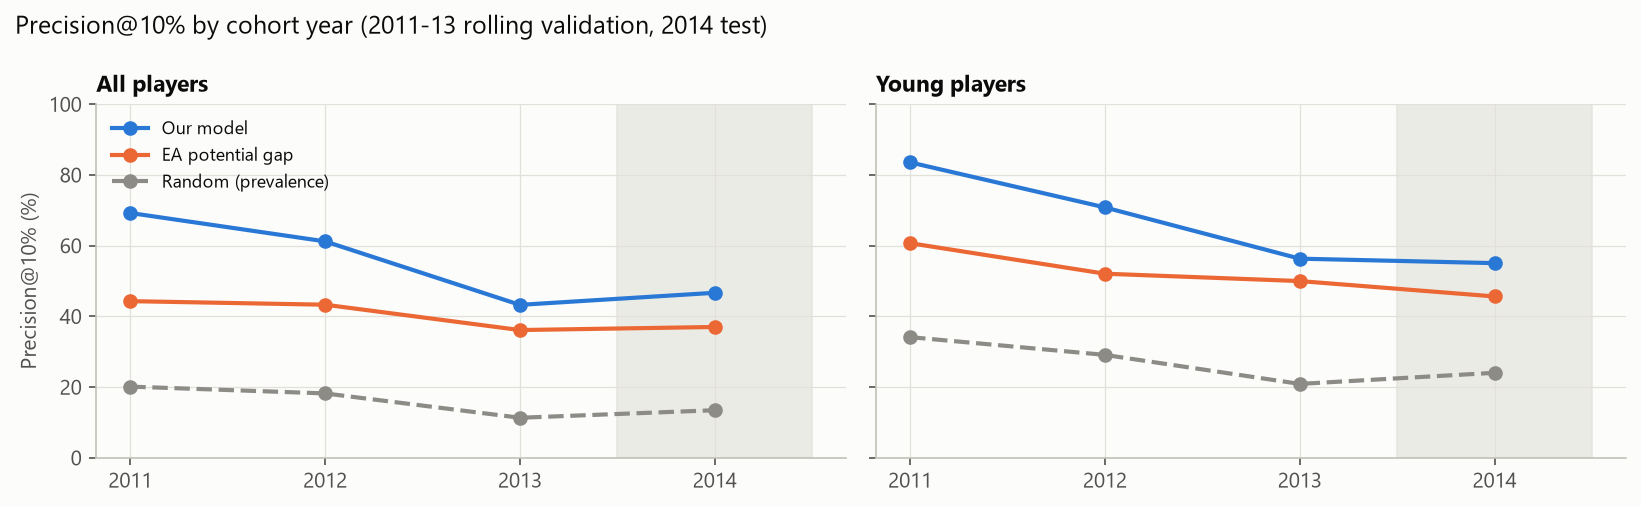

In [5]:
display(Image(B_FIGURES / "precision_by_year.png"))

## 2 · Uncertainty: player-clustered bootstrap
Players recur across years, so we resample **player IDs** with replacement (all of a player's rows
travel together), recompute each year's watchlist and metrics, and average over years. In the
single test year each player appears once, so this equals a row bootstrap there. The same draws are
used for every model, so differences against EA's list are **paired**. `share_reps_not_better` is the
share of replicates where the model does not beat the reference (a one-sided bootstrap p-value).

In [6]:
ci, diffs = r["bootstrap"], r["differences"]
key = []
for c, s in r["selection"].items():
    key.append(ci[(ci.cohort == c) & (((ci.model == s["model"]) & (ci.feature_set == s["feature_set"])
                                      & (ci.train_scope == s["train_scope"]))
                                     | ((ci.model == "ea_gap") & (ci.train_scope == c)) | (ci.model == "random"))])
pd.concat(key).query("metric != 'hits'").pivot_table(
    index=["period", "cohort", "model"], columns="metric", values=["estimate", "ci_low", "ci_high"]).round(3)

ci_high                                               ci_low                                             estimate                                   
metric                              average_precision precision_at_10pct recall_at_10pct average_precision precision_at_10pct recall_at_10pct average_precision precision_at_10pct recall_at_10pct
period               cohort model                                                                                                                                                                 
test_2014            all    ea_gap              0.332              0.423           0.311             0.263              0.323           0.241             0.294              0.370           0.274
                            logreg              0.450              0.517           0.379             0.365              0.412           0.309             0.406              0.467           0.346
                            random              0.146              0.146           0.100             0.124              0.124           0.100             0.135              0.135           0.100
                     young  ea_gap              0.399              0.543           0.225             0.307              0.377           0.158             0.349              0.457           0.190
                            hist_gb             0.542              0.645           0.264             0.433              0.471           0.200             0.486              0.551           0.229
                            random              0.263              0.263           0.100             0.218              0.218           0.100             0.241              0.241           0.100
validation_2011_2013 all    ea_gap              0.365              0.443           0.276             0.323              0.380           0.239             0.343              0.413           0.259
                            logreg              0.529              0.607           0.370             0.483              0.549           0.335             0.507              0.579           0.353
                            random              0.173              0.173           0.100             0.159              0.159           0.100             0.166              0.166           0.100
                     young  ea_gap              0.454              0.590           0.214             0.399              0.490           0.179             0.424              0.543           0.198
                            hist_gb             0.589              0.744           0.268             0.532              0.651           0.234             0.560              0.702           0.252
                            random              0.293              0.293           0.100             0.267              0.267           0.099             0.281              0.281           0.100

In [7]:
d = []
for c, s in r["selection"].items():
    d.append(diffs[(diffs.cohort == c) & (diffs.model == s["model"]) & (diffs.feature_set == s["feature_set"])
                   & (diffs.train_scope == s["train_scope"])])
pd.concat(d)[["period", "cohort", "model", "versus", "metric", "difference", "ci_low", "ci_high",
              "share_reps_not_better"]]

,period,cohort,model,versus,metric,difference,ci_low,ci_high,share_reps_not_better
36,test_2014,all,logreg,ea_gap,precision_at_10pct,0.097,0.041,0.144,0.001
37,test_2014,all,logreg,random,precision_at_10pct,0.332,0.282,0.378,0.000
38,test_2014,all,logreg,ea_gap,recall_at_10pct,0.072,0.030,0.107,0.001
39,test_2014,all,logreg,random,recall_at_10pct,0.246,0.210,0.279,0.000
40,test_2014,all,logreg,ea_gap,average_precision,0.112,0.077,0.147,0.000
41,test_2014,all,logreg,random,average_precision,0.272,0.232,0.312,0.000
42,test_2014,all,logreg,ea_gap,hits,35.000,14.975,52.000,0.001
43,test_2014,all,logreg,random,hits,120.221,102.014,136.835,0.000
340,validation_2011_2013,all,logreg,ea_gap,precision_at_10pct,0.167,0.136,0.198,0.000
341,validation_2011_2013,all,logreg,random,precision_at_10pct,0.413,0.386,0.438,0.000


## 3 · Scouting simulation on the 2014 cohort (headline)
The action: on 1 August 2014 a scouting team can follow 10% of the players who started a league match
in 2013/14. We compare three ways to choose them: our selected model, EA's potential-minus-overall
gap, and a random list (expected value and the 95% range of random lists, from the hypergeometric
distribution). A "hit" is a player whose rating rose by at least the year's median change + 3 by
1 August 2015.

In [8]:
r["scouting"][["cohort", "strategy", "budget", "players_listed", "hits", "misses", "precision",
               "share_of_all_breakouts", "hits_ci_low", "hits_ci_high", "note"]]

,cohort,strategy,budget,players_listed,hits,misses,precision,share_of_all_breakouts,hits_ci_low,hits_ci_high,note
0,all,model watchlist,362,362,169.000,193.000,0.467,0.346,149.000,187.025,
1,all,EA potential-gap watchlist,362,362,134.000,228.000,0.370,0.274,116.975,153.000,
2,all,on both lists,362,182,93.000,89.000,0.511,0.190,NaN,NaN,
3,all,model only,362,180,76.000,104.000,0.422,0.155,NaN,NaN,
4,all,EA only,362,180,41.000,139.000,0.228,0.084,NaN,NaN,
5,all,union of both lists,362,542,210.000,332.000,0.387,0.429,NaN,NaN,uses up to 2x the budget
6,all,random watchlist (expected),362,362,48.779,313.221,0.135,0.100,37.000,61.000,95% of random lists hit 37-61 breakouts
7,young,model watchlist,138,138,76.000,62.000,0.551,0.229,65.000,89.000,
8,young,EA potential-gap watchlist,138,138,63.000,75.000,0.457,0.190,52.000,75.000,
9,young,on both lists,138,59,34.000,25.000,0.576,0.102,NaN,NaN,


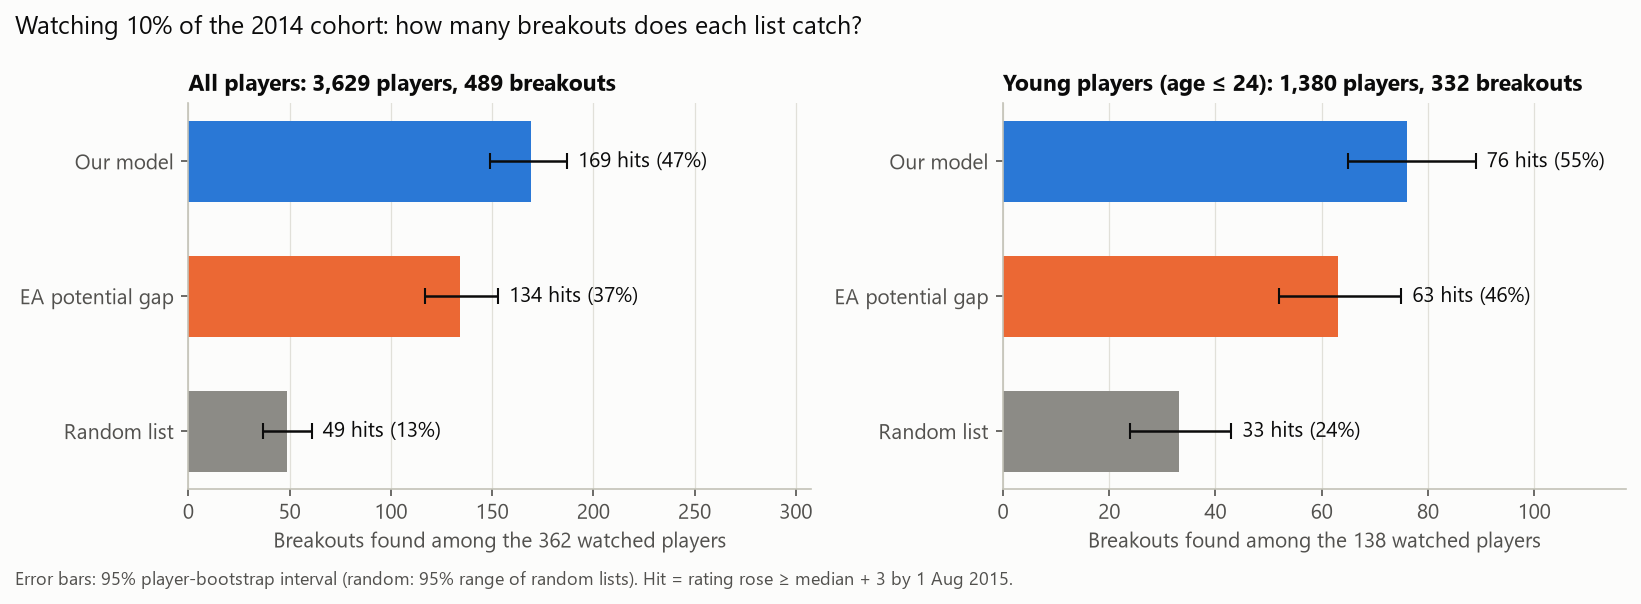

In [9]:
display(Image(B_FIGURES / "headline_scouting_2014.png"))

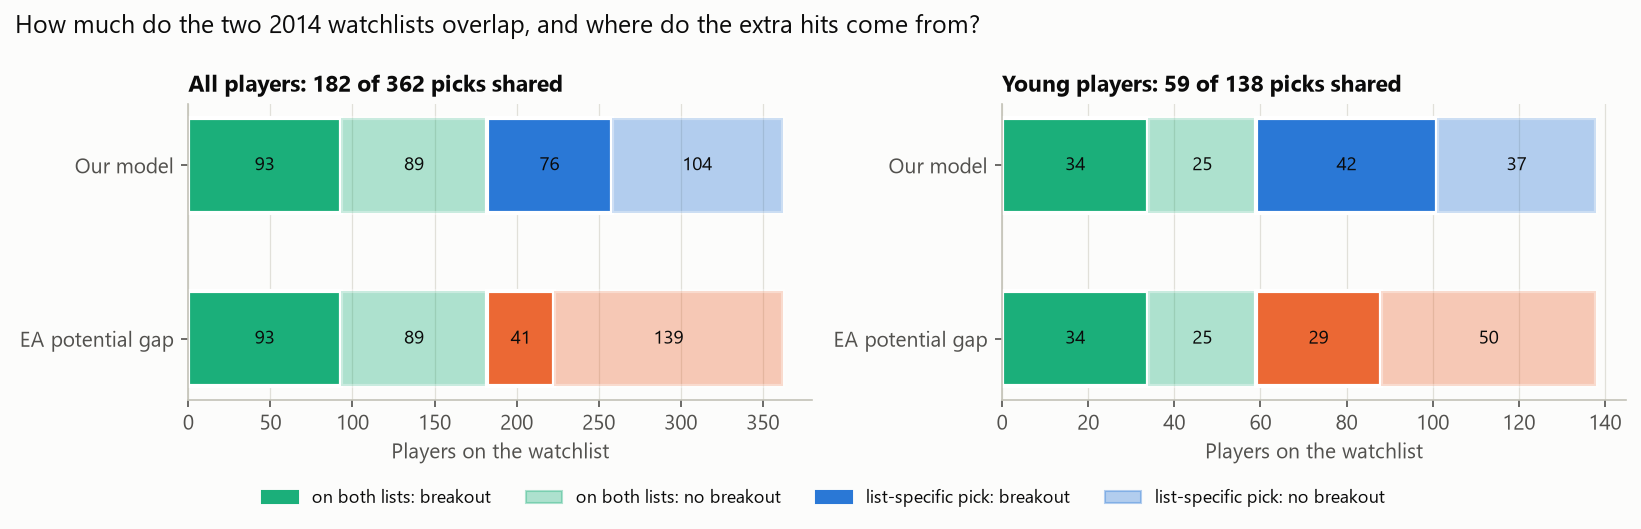

In [10]:
display(Image(B_FIGURES / "watchlist_overlap_2014.png"))

**Who does each list pick?** Profiles of the two watchlists against the whole cohort and against the
players who actually broke out.

In [11]:
r["profile"].set_index(["cohort", "group"]).T

cohort                                                                 all                                                                                                        \
group                                                      model watchlist                                       EA watchlist                                       whole cohort   
players                                                                362                                                362                                               3629   
breakout_rate                                                        0.467                                              0.370                                              0.135   
mean_age                                                            21.481                                             20.884                                             26.561   
share_age_21_or_less                                                 0.652                                              0.765                                              0.149   
mean_overall_rating                                                 61.655                                             64.459                                             70.228   
mean_potential_gap                                                   9.699                                             12.224                                              3.958   
mean_prev_season_starts                                             12.370                                             10.771                                             16.951   
share_goalkeeper                                                     0.080                                              0.055                                              0.084   
share_defender                                                       0.312                                              0.331                                              0.340   
share_midfielder                                                     0.425                                              0.434                                              0.402   
share_forward                                                        0.182                                              0.180                                              0.174   
top_leagues              Poland Ekstraklasa 16%; France Ligue 1 15%; Sc...  Scotland Premier League 16%; France Ligue 1 15...  Italy Serie A 13%; Spain LIGA BBVA 12%; France...   

cohort                                                                                                                  young                                                     \
group                                                     actual breakouts                                    model watchlist                                       EA watchlist   
players                                                                489                                                138                                                138   
breakout_rate                                                        1.000                                              0.551                                              0.457   
mean_age                                                            23.750                                             20.489                                             20.246   
share_age_21_or_less                                                 0.368                                              0.833                                              0.870   
mean_overall_rating                                                 66.219                                             59.341                                             62.797   
mean_potential_gap                                                   6.939                                             11.406                                             14.659   
mean_prev_season_starts                

In [12]:
lg = r["leagues"].pivot_table(index=["cohort", "league"], columns="list", values="players", fill_value=0)
lg

list                                EA  cohort  model
cohort league                                        
all    Belgium Jupiler League    8.000  69.000  5.000
       England Premier League   28.000 449.000 23.000
       France Ligue 1           53.000 449.000 54.000
       Germany 1. Bundesliga    36.000 399.000 31.000
       Italy Serie A            34.000 475.000 25.000
       Netherlands Eredivisie   29.000 328.000 22.000
       Poland Ekstraklasa       16.000 284.000 59.000
       Portugal Liga ZON Sagres 29.000 309.000 33.000
       Scotland Premier League  58.000 219.000 38.000
       Spain LIGA BBVA          26.000 452.000 38.000
       Switzerland Super League 45.000 196.000 34.000
young  Belgium Jupiler League    2.000  30.000  3.000
       England Premier League   15.000 127.000 13.000
       France Ligue 1           21.000 177.000 32.000
       Germany 1. Bundesliga    18.000 156.000 17.000
       Italy Serie A            13.000 131.000  8.000
       Netherlands Eredivisie    8.000 184.000  1.000
       Poland Ekstraklasa        5.000 101.000 16.000
       Portugal Liga ZON Sagres  6.000 133.000  2.000
       Scotland Premier League  25.000 110.000 17.000
       Spain LIGA BBVA           6.000 140.000 12.000
       Switzerland Super League 19.000  91.000 17.000

**Is the 10% budget cherry-picked?** Precision at other budgets in 2014 (computed after the fact;
the budget was fixed in the proposal).

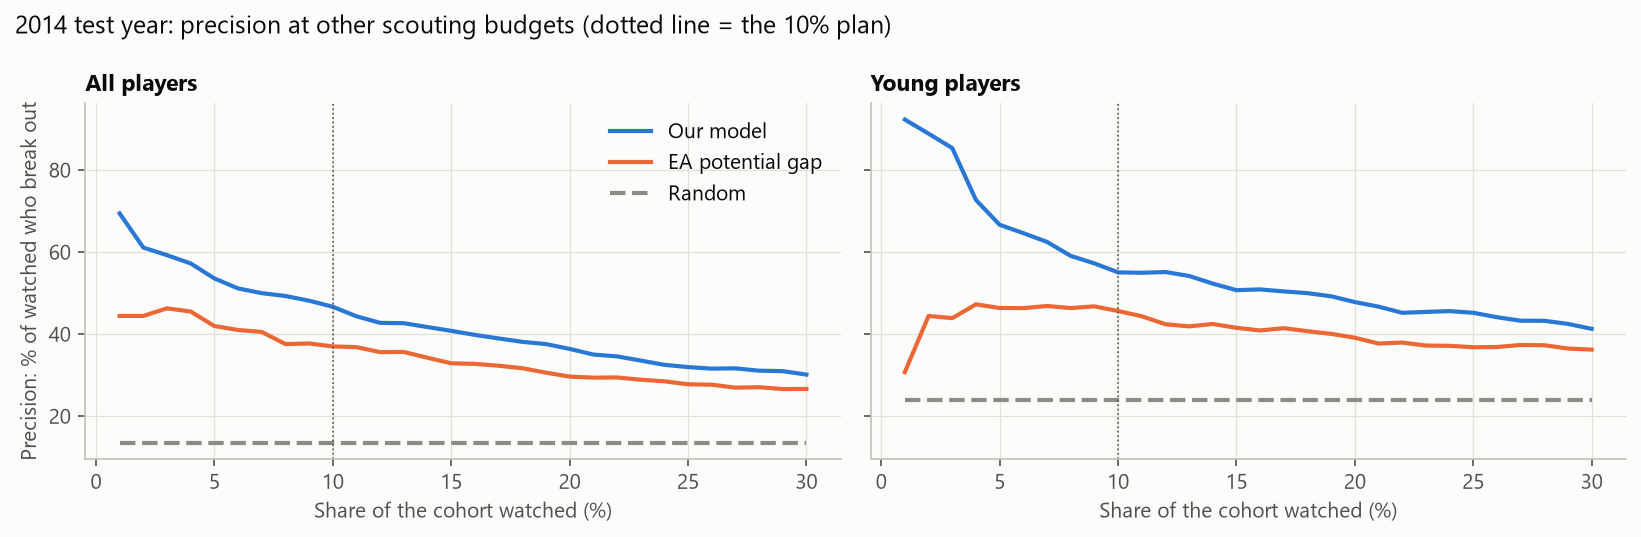

In [13]:
display(Image(B_FIGURES / "precision_by_budget_2014.png"))

## 4 · Explainability
**Permutation importance.** For each rolling validation fold (train on years before *v*, score year
*v*) we shuffle a group of related columns jointly and record the drop in average precision (and in
Precision@10%). Grouping matters: the 33 skills are highly correlated, so shuffling one skill at a
time understates them. The fold mean is the primary estimate; the 2014 value (final 2009–13 refit
scored on 2014) is shown only as a descriptive check — nothing is chosen from it.

In [14]:
r["importance_groups"][["cohort", "group", "ap_drop_validation", "ap_drop_fold_min", "ap_drop_fold_max",
                         "p10_drop_validation", "ap_drop_test", "p10_drop_test"]]

,cohort,group,ap_drop_validation,ap_drop_fold_min,ap_drop_fold_max,p10_drop_validation,ap_drop_test,p10_drop_test
10,all,team context,0.164,0.155,0.174,0.173,0.127,0.139
6,all,overall rating,0.096,0.092,0.103,0.099,0.064,0.069
7,all,playing time,0.093,0.072,0.108,0.085,0.080,0.088
1,all,"EA potential (potential, gap, change)",0.079,0.066,0.096,0.077,0.061,0.072
2,all,age,0.069,0.058,0.078,0.069,0.052,0.064
4,all,league,0.056,0.030,0.089,0.058,0.063,0.091
0,all,33 skill ratings,0.015,0.010,0.019,0.017,0.019,0.029
8,all,position,0.005,-0.000,0.008,0.005,0.005,0.013
5,all,line-up data coverage,0.004,0.002,0.006,0.003,-0.000,-0.000
3,all,body and EA tags,0.003,-0.001,0.007,-0.003,0.005,0.019


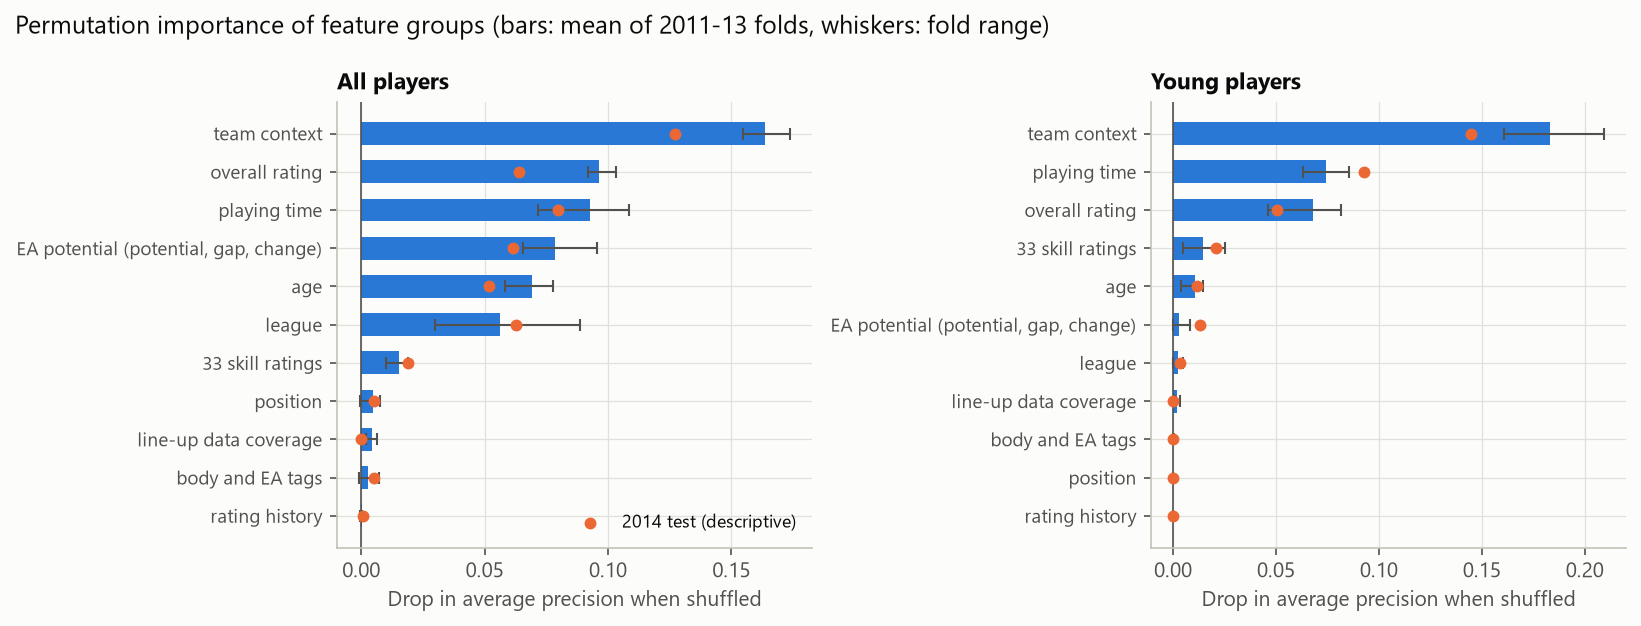

In [15]:
display(Image(B_FIGURES / "permutation_importance_groups.png"))

In [16]:
r["importance_columns"].groupby("cohort").head(12)[["cohort", "group", "ap_drop_validation", "ap_drop_test"]]

,cohort,group,ap_drop_validation,ap_drop_test
50,all,starts,0.111,0.092
31,all,overall_rating,0.096,0.063
1,all,age_years,0.067,0.051
26,all,league,0.058,0.062
37,all,potential_gap,0.051,0.058
41,all,rating_vs_teammates,0.050,0.043
8,all,club_ppg,0.045,0.040
35,all,potential,0.034,0.015
53,all,team_mean_rating,0.029,0.023
54,all,team_rating_rank_pct,0.011,0.014


**Standardised logistic-regression coefficients** (log-odds change per 1 SD, other features held
fixed) for workstream 3's logistic pipeline fitted on 2009–2013. For the young cohort the selected
model is gradient boosting, so the coefficients come from the best validated logistic regression on
the same feature set (a transparent stand-in, not the scoring model). If the tuned setting replaced
skills with principal components, the components' loadings are listed below. Coefficients of
correlated features (overall rating, potential, gap; team rating and rating vs teammates) must be read
together: they show conditional, not marginal, associations.

In [17]:
r["coefficients"].groupby("cohort").head(15)[["cohort", "source", "term", "coefficient_per_sd", "ci_low", "ci_high", "ci_excludes_zero"]]

,cohort,source,term,coefficient_per_sd,ci_low,ci_high,ci_excludes_zero
36,all,selected model,league_Switzerland Super League,-1.090,-1.299,-0.881,True
34,all,selected model,league_Scotland Premier League,-1.043,-1.198,-0.878,True
13,all,selected model,starts,1.025,0.765,1.268,True
35,all,selected model,league_Spain LIGA BBVA,0.766,0.608,0.933,True
33,all,selected model,league_Portugal Liga ZON Sagres,0.683,0.565,0.821,True
30,all,selected model,league_Italy Serie A,0.608,0.448,0.765,True
0,all,selected model,overall_rating,-0.583,-0.655,-0.522,True
4,all,selected model,age_years,-0.506,-0.574,-0.439,True
15,all,selected model,club_ppg,0.481,0.415,0.547,True
27,all,selected model,league_England Premier League,0.464,0.293,0.602,True


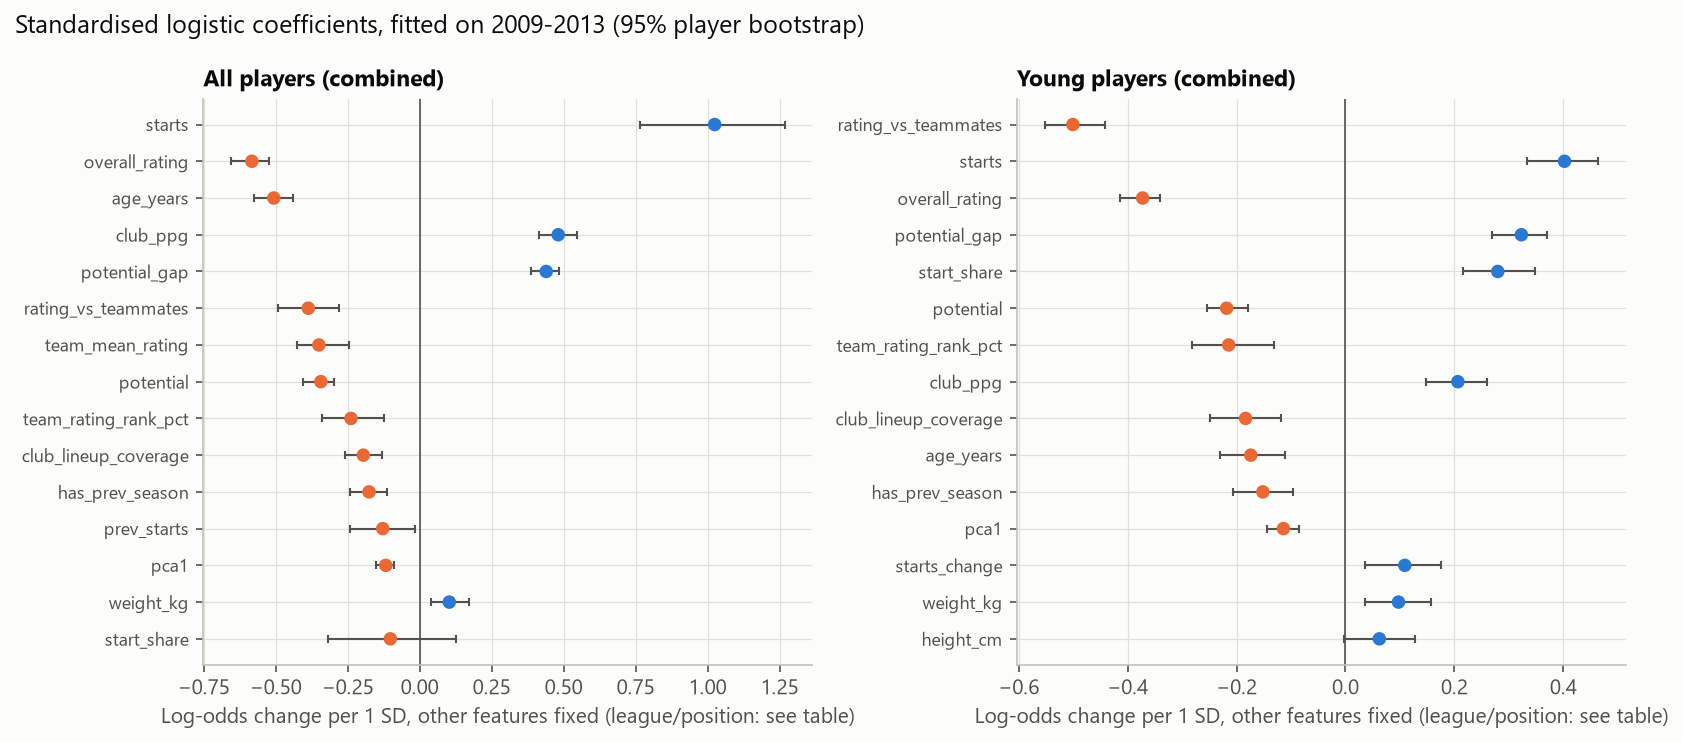

In [18]:
display(Image(B_FIGURES / "logistic_coefficients.png"))

In [19]:
pl = r["pca_loadings"]
pl[pl["rank"] <= 4] if len(pl) else "no PCA in the logistic settings"

,cohort,component,skill,loading,rank
0,all,pca0,ball_control,0.239,1
1,all,pca0,short_passing,0.232,2
2,all,pca0,dribbling,0.223,3
3,all,pca0,crossing,0.220,4
33,all,pca1,marking,0.388,1
34,all,pca1,standing_tackle,0.380,2
35,all,pca1,sliding_tackle,0.373,3
36,all,pca1,aggression,0.292,4
66,all,pca2,gk_kicking,0.453,1
67,all,pca2,gk_handling,0.343,2


**Feature-set comparison (the circularity question).** EA's potential is a subjective EA judgement and
the label is also an EA rating. If the model's edge came only from EA's own potential, removing it
would erase the gain. The contrasts below are paired bootstrap differences in Precision@10% within the
selected model family.

In [20]:
fsc = r["feature_set_contrasts"]
fsc[fsc.metric.isin(["precision_at_10pct", "average_precision"])][
    ["period", "cohort", "model", "contrast", "metric", "difference", "ci_low", "ci_high", "share_reps_not_better"]]

,period,cohort,model,contrast,metric,difference,ci_low,ci_high,share_reps_not_better
0,test_2014,all,logreg,rating_no_potential - ea_gap_only,precision_at_10pct,0.052,0.003,0.105,0.024
2,test_2014,all,logreg,rating_no_potential - ea_gap_only,average_precision,0.060,0.026,0.093,0.000
4,test_2014,all,logreg,rating_only - rating_no_potential,precision_at_10pct,0.017,-0.014,0.030,0.246
6,test_2014,all,logreg,rating_only - rating_no_potential,average_precision,0.002,-0.008,0.012,0.335
8,test_2014,all,logreg,combined - rating_only,precision_at_10pct,0.028,-0.011,0.069,0.096
10,test_2014,all,logreg,combined - rating_only,average_precision,0.051,0.027,0.071,0.000
12,test_2014,all,logreg,combined - rating_no_potential,precision_at_10pct,0.044,-0.003,0.080,0.040
14,test_2014,all,logreg,combined - rating_no_potential,average_precision,0.053,0.029,0.073,0.000
16,test_2014,young,hist_gb,rating_no_potential - ea_gap_only,precision_at_10pct,0.036,-0.065,0.145,0.269
18,test_2014,young,hist_gb,rating_no_potential - ea_gap_only,average_precision,0.043,-0.002,0.093,0.035


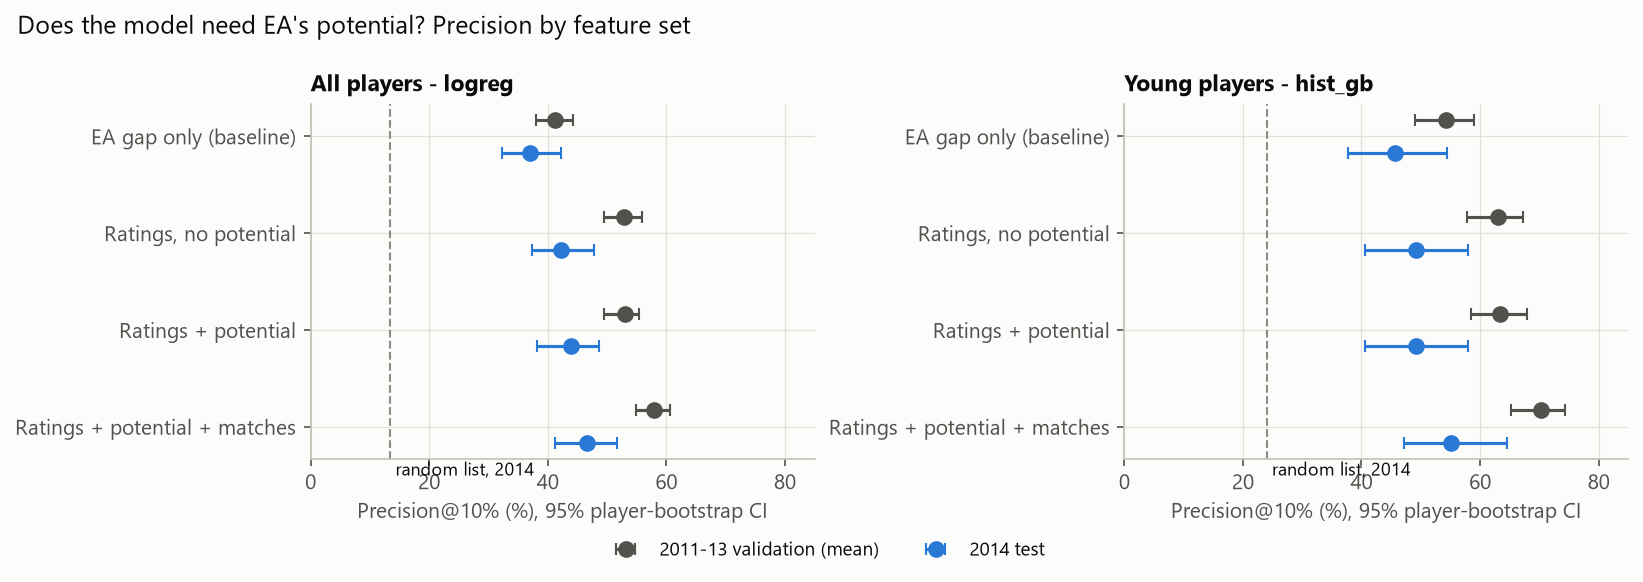

In [21]:
display(Image(B_FIGURES / "feature_set_comparison.png"))

## 5 · Sensitivity analyses
Labels are recomputed from the database inside `src/evaluation.py` (the main label is re-derived too
as a check). For each scenario the selected pipeline is re-run through the rolling validation folds
and the 2009–2013 → 2014 refit, and compared with EA's list under the same label.

* **Max rating label**: the follow-up rating is the highest in [1 Aug *y*, 1 Aug *y*+1) instead of the
  last; the yearly median is recomputed on that change.
* **Horizon ≥ 180 days**: rows whose two paired ratings are under 180 days apart are dropped from
  training and evaluation.
* **Threshold median + 2 / + 4**: the arbitrary "+3" is moved either way.

In [22]:
r["label_stats"]

,year,rows,breakout,breakout_max,median_change_max,breakout_t2,breakout_t4,share_horizon_lt_180,label_recheck_ok,max_label_flips
0,2009,3317,0.257,0.207,1.000,0.347,0.191,0.000,1.000,215
1,2010,3535,0.168,0.190,0.000,0.248,0.119,0.000,1.000,77
2,2011,3618,0.201,0.147,1.000,0.298,0.135,0.000,1.000,236
3,2012,3741,0.182,0.147,1.000,0.273,0.129,0.000,1.000,193
4,2013,3791,0.113,0.127,0.000,0.188,0.064,0.064,1.000,51
5,2014,3629,0.135,0.149,0.000,0.218,0.080,0.074,1.000,50


In [23]:
r["sensitivity"][["scenario", "cohort", "prevalence_test", "val_precision_selected", "val_precision_ea",
                   "test_precision_selected", "test_precision_ea", "test_diff", "test_diff_ci_low",
                   "test_diff_ci_high", "model_beats_ea_validation", "model_beats_ea_test"]]

,scenario,cohort,prevalence_test,val_precision_selected,val_precision_ea,test_precision_selected,test_precision_ea,test_diff,test_diff_ci_low,test_diff_ci_high,model_beats_ea_validation,model_beats_ea_test
0,base,all,0.135,0.579,0.413,0.467,0.370,0.097,0.041,0.144,True,True
1,base,young,0.241,0.702,0.543,0.551,0.457,0.094,0.014,0.188,True,True
2,max_rating_label,all,0.149,0.534,0.380,0.464,0.387,0.077,0.030,0.133,True,True
3,max_rating_label,young,0.257,0.662,0.500,0.543,0.471,0.072,-0.007,0.174,True,True
4,horizon_ge_180d,all,0.141,0.582,0.415,0.485,0.387,0.098,0.042,0.149,True,True
5,horizon_ge_180d,young,0.251,0.708,0.544,0.597,0.473,0.124,0.008,0.202,True,True
6,threshold_plus2,all,0.218,0.675,0.505,0.583,0.497,0.086,0.028,0.138,True,True
7,threshold_plus2,young,0.343,0.747,0.618,0.674,0.580,0.094,0.022,0.203,True,True
8,threshold_plus4,all,0.080,0.483,0.324,0.351,0.279,0.072,0.025,0.122,True,True
9,threshold_plus4,young,0.158,0.609,0.430,0.428,0.333,0.094,0.007,0.181,True,True


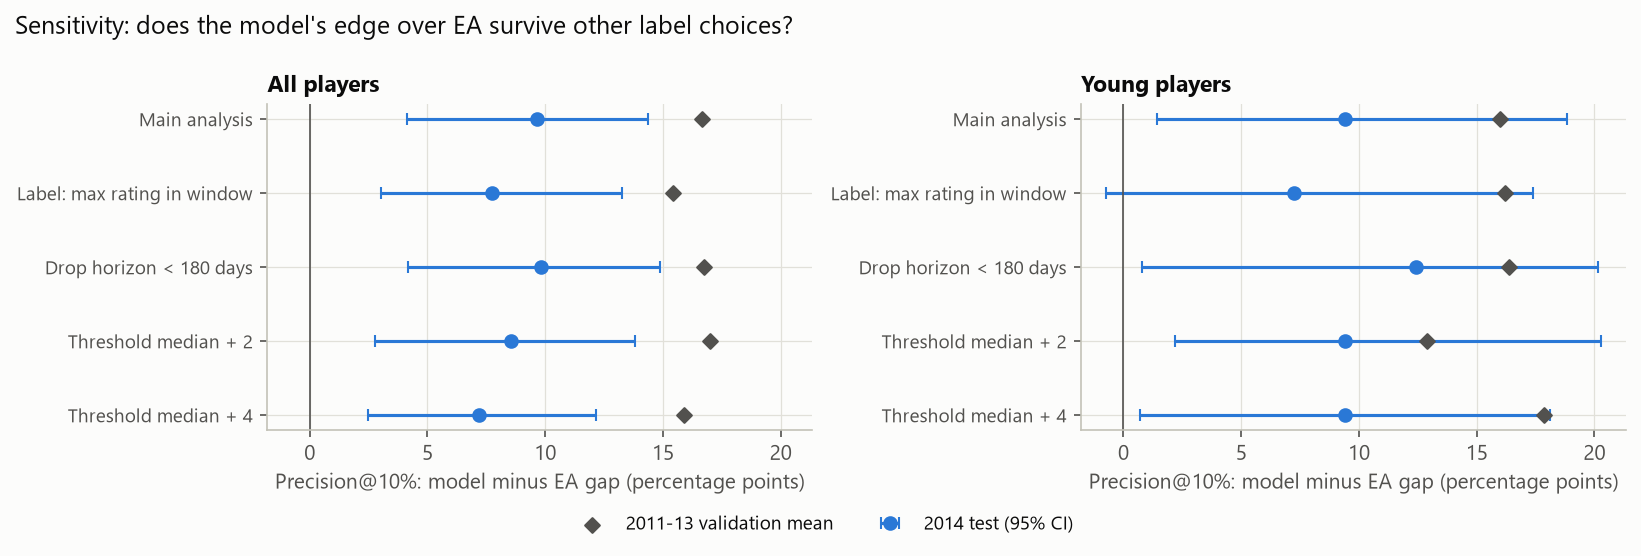

In [24]:
display(Image(B_FIGURES / "sensitivity.png"))

## 6 · Supplementary EA-independent check: next-season starts
EA ratings define both a feature and the label. As an outcome EA does not set, we count league starts
in 2014/15 (from the match line-ups) for watchlisted vs other 2014 players. Players who left the 11
leagues count as 0. The adjusted difference controls linearly for previous-season starts, age and
current rating, because the lists favour young players whose playing time is changing anyway. This is
descriptive, not causal.

In [25]:
r["next_starts"]

,cohort,list,listed,mean_next_starts_listed,mean_next_starts_others,share_any_start_listed,share_any_start_others,mean_change_listed,mean_change_others,raw_difference,raw_ci_low,raw_ci_high,adjusted_difference,adjusted_ci_low,adjusted_ci_high
0,all,model,362,12.210,14.436,0.757,0.784,-0.160,-3.022,-2.226,-3.395,-0.955,0.140,-1.144,1.378
1,all,EA potential gap,362,10.986,14.571,0.738,0.786,0.215,-3.064,-3.585,-4.833,-2.378,-1.423,-2.714,-0.191
2,young,model,138,10.341,14.185,0.688,0.795,1.058,-0.817,-3.845,-5.649,-1.752,1.055,-0.931,3.172
3,young,EA potential gap,138,9.746,14.251,0.674,0.796,1.080,-0.820,-4.505,-6.326,-2.567,-0.431,-2.449,1.558


In [26]:
det = r["next_detail"]
det.groupby(["cohort", "breakout"]).agg(players=("next_starts", "size"), mean_next_starts=("next_starts", "mean"),
                                        mean_change=("start_change", "mean"))

players  mean_next_starts  mean_change
cohort breakout                                        
all    0            3140            13.265       -3.920
       1             489            20.309        4.861
young  0            1048            12.192       -2.311
       1             332            18.880        4.678

## 7 · Conclusions
The written conclusions, assumptions and limitations are in `report/04_evaluation_results.md`, and
every judgement call is logged in `docs/decisions/04_evaluation.md`. The cell below prints the
headline numbers used there.

In [27]:
for c in COHORTS:
    t = r["scouting"][r["scouting"].cohort == c].set_index("strategy")
    mdl, ea, rnd = t.loc["model watchlist"], t.loc["EA potential-gap watchlist"], t.loc["random watchlist (expected)"]
    print(f"{c:5s}: watch {int(mdl.budget)} of {int(mdl.cohort_size)}; model {mdl.hits:.0f} hits ({mdl.precision:.1%}, "
          f"95% CI {mdl.hits_ci_low:.0f}-{mdl.hits_ci_high:.0f}); EA {ea.hits:.0f} ({ea.precision:.1%}); "
          f"random {rnd.hits:.1f} ({rnd.precision:.1%}); overlap {t.loc['on both lists'].players_listed:.0f}")

all  : watch 362 of 3629; model 169 hits (46.7%, 95% CI 149-187); EA 134 (37.0%); random 48.8 (13.5%); overlap 182
young: watch 138 of 1380; model 76 hits (55.1%, 95% CI 65-89); EA 63 (45.7%); random 33.2 (24.1%); overlap 59
